# TruthSeeker 2023 — Exploratory Data Analysis

EDA for **TweetGuard**, the companion repo to *"Fake Tweets Detection using Bi-LSTM with GloVe Embedding"* (ICCIKE 2025, DOI [10.1109/ICCIKE67021.2025.11318261](https://doi.org/10.1109/ICCIKE67021.2025.11318261)).

The dataset is [TruthSeeker 2023](https://www.unb.ca/cic/datasets/truthseeker-2023.html) (UNB CIC), fetched from its Kaggle mirror by `src.data.download` — no data files live in this repository. Cleaning here reuses `src.data.preprocess.load_and_clean`, so the notebook sees exactly what the models train on (before augmentation).

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from tqdm import TqdmWarning

warnings.filterwarnings("ignore", category=TqdmWarning)  # cosmetic notebook-widget warning

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from src.data.download import download_dataset
from src.data.preprocess import load_and_clean

# Chart theme (validated light-surface palette). Entity colors are fixed across
# every figure: real = blue, fake = green.
COLOR_REAL, COLOR_FAKE = "#2a78d6", "#008300"
INK, INK_2, MUTED, GRID, AXIS, SURFACE = (
    "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
)
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "figure.dpi": 110,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## Raw data glimpse

`Truth_Seeker_Model_Dataset.csv` — one row per tweet, labelled by `BinaryNumTarget` (1 = real, 0 = fake).

In [2]:
csv_path = download_dataset()
raw = pd.read_csv(csv_path)
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Columns: {list(raw.columns)}")
print("\nMissing values in the columns the pipeline uses:")
print(raw[["tweet", "BinaryNumTarget"]].isna().sum().to_string())
raw[["statement", "tweet", "BinaryNumTarget"]].head(3)

Raw shape: 134,198 rows x 9 columns
Columns: ['Unnamed: 0', 'author', 'statement', 'target', 'BinaryNumTarget', 'manual_keywords', 'tweet', '5_label_majority_answer', '3_label_majority_answer']

Missing values in the columns the pipeline uses:
tweet              0
BinaryNumTarget    0


,statement,tweet,BinaryNumTarget
0,End of eviction moratorium means millions of A...,@POTUS Biden Blunders - 6 Month Update\n\nInfl...,1.0
1,End of eviction moratorium means millions of A...,@S0SickRick @Stairmaster_ @6d6f636869 Not as m...,1.0
2,End of eviction moratorium means millions of A...,THE SUPREME COURT is siding with super rich pr...,1.0


## Class balance

After the paper's cleaning (missing text → empty string, empty tweets dropped).

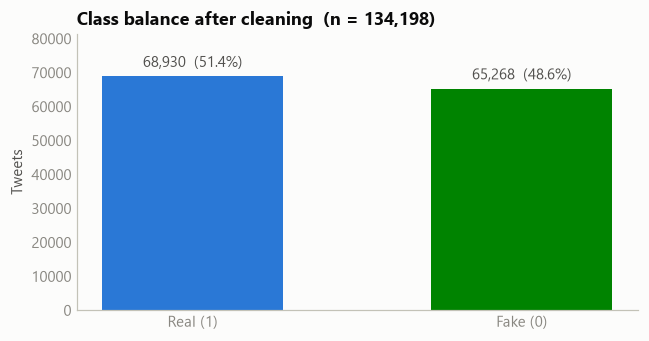

In [3]:
frame = load_and_clean(csv_path)
counts = frame["label"].value_counts().reindex([1, 0])

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.grid(False)  # two direct-labelled bars need no grid
bars = ax.bar(
    ["Real (1)", "Fake (0)"], counts.to_numpy(),
    color=[COLOR_REAL, COLOR_FAKE], width=0.55,
)
for bar, n in zip(bars, counts):
    ax.annotate(
        f"{n:,}  ({n / len(frame):.1%})",
        (bar.get_x() + bar.get_width() / 2, n),
        xytext=(0, 4), textcoords="offset points",
        ha="center", va="bottom", fontsize=10, color=INK_2,
    )
ax.set_title(f"Class balance after cleaning  (n = {len(frame):,})")
ax.set_ylabel("Tweets")
ax.set_ylim(0, counts.max() * 1.18)
ax.tick_params(length=0)
plt.tight_layout()

## Tweet lengths

Distributions per class, clipped at the 99th percentile so a handful of extreme outliers don't flatten the picture.

,words,chars
label,,
fake,39.0,239.0
real,35.0,219.0


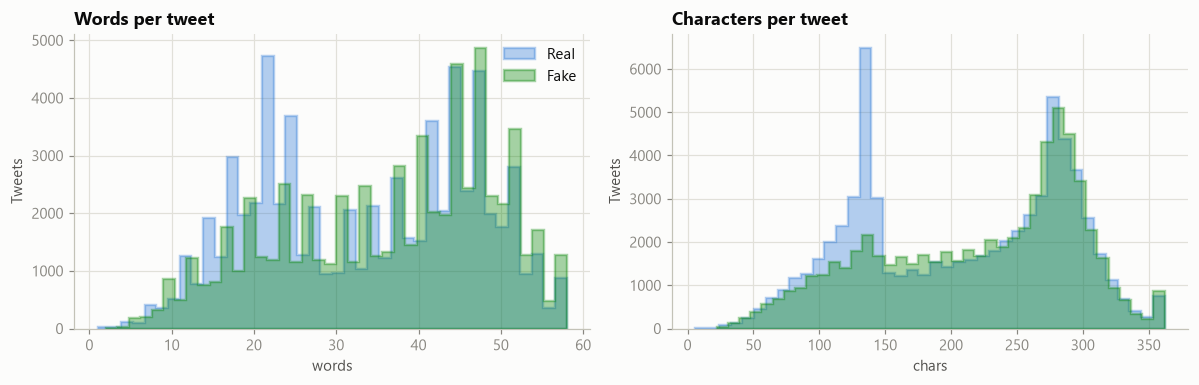

In [4]:
frame["words"] = frame["tweet"].str.split().str.len()
frame["chars"] = frame["tweet"].str.len()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title in [(axes[0], "words", "Words per tweet"), (axes[1], "chars", "Characters per tweet")]:
    upper = frame[col].quantile(0.99)
    for value, color, name in [(1, COLOR_REAL, "Real"), (0, COLOR_FAKE, "Fake")]:
        subset = frame.loc[frame["label"] == value, col].clip(upper=upper)
        ax.hist(
            subset, bins=40, histtype="stepfilled",
            alpha=0.35, color=color, edgecolor=color, linewidth=1.6, label=name,
        )
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel("Tweets")
axes[0].legend(frameon=False)
plt.tight_layout()

frame.groupby("label")[["words", "chars"]].median().rename(index={0: "fake", 1: "real"})

## Most frequent words

Top 20 alphabetic tokens after removing English stop words (scikit-learn's list) — a quick look at what the corpus talks about.

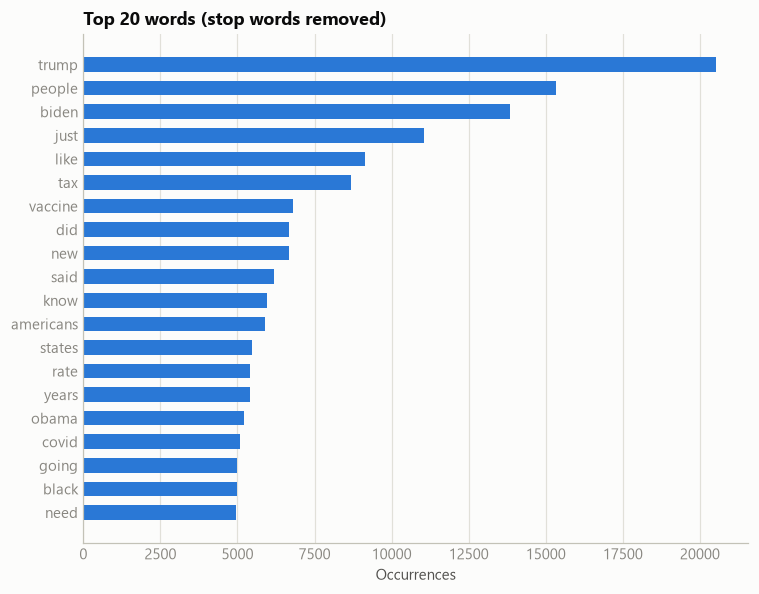

In [5]:
def top_words(texts, k=20):
    """Count alphabetic, non-stop-word tokens of length > 2."""
    counter = Counter()
    for text in texts:
        counter.update(
            w for w in text.lower().split()
            if w.isalpha() and len(w) > 2 and w not in ENGLISH_STOP_WORDS
        )
    return counter.most_common(k)

pairs = top_words(frame["tweet"])
words = [w for w, _ in pairs][::-1]
freqs = [n for _, n in pairs][::-1]

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.grid(False)
ax.xaxis.grid(True)
ax.barh(words, freqs, color=COLOR_REAL, height=0.62)
ax.set_title("Top 20 words (stop words removed)")
ax.set_xlabel("Occurrences")
ax.tick_params(length=0)
plt.tight_layout()

## Observations

- **Near-balanced classes.** After cleaning, 68,930 real (51.4%) vs 65,268 fake (48.6%) of
  134,198 tweets. This Kaggle mirror has no missing values in `tweet`/`BinaryNumTarget`, so the
  pipeline's missing-value handling acts as a safeguard rather than a correction.
- **Bimodal tweet lengths.** Both classes pile up near the historical 140-character and current
  280-character limits. Fake-labelled tweets run slightly longer (median 39 vs 35 words,
  239 vs 219 characters) — a weak signal on its own, but consistent across both length views.
- **Topical vocabulary.** The corpus is dominated by US politics and pandemic terms (*trump,
  people, biden, tax, vaccine, obama, covid*), reflecting TruthSeeker's PolitiFact-derived
  claims. Models trained here inherit that domain: strong on political misinformation,
  untested elsewhere.
- **Modelling consequence.** Tweets are short (≲60 words), so the paper's padded fixed-length
  sequences with a BiLSTM are a good fit. Word-swap augmentation (p = 0.2, growing the data to
  200,000 rows) happens downstream in `src.data.preprocess` — everything above is
  pre-augmentation.